# Predictive Maintenance — RUL Model (Clean Pipeline)
NASA C-MAPSS FD001 — XGBoost Regressor

This notebook is a single linear pipeline: one load, one cleaning pass,
one leakage-safe validation scheme, one ablation test, one final model.
No duplicate cells, no re-imports, no dead branches.

If `../data/train_FD001.txt` etc. are not found, a synthetic C-MAPSS-style
fallback is generated so the notebook still runs end-to-end — swap in your
real files and nothing else changes.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
RUL_CLIP = 125  # standard C-MAPSS piecewise RUL ceiling
np.random.seed(RANDOM_STATE)


## 1. Load data

In [6]:
DATA_DIR = "../data"

COLS = (
    ["engine_id", "cycle", "op1", "op2", "op3"]
    + [f"sensor{i}" for i in range(1, 22)]
)

def _load_real():
    train = pd.read_csv(f"{DATA_DIR}/train_FD001.txt", sep=r"\s+", header=None)
    test = pd.read_csv(f"{DATA_DIR}/test_FD001.txt", sep=r"\s+", header=None)
    rul_test = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt", sep=r"\s+", header=None)
    train.columns = COLS
    test.columns = COLS
    rul_test.columns = ["true_RUL"]
    return train, test, rul_test

def _generate_synthetic(n_engines=100):
    """Fallback only — used if real C-MAPSS files are not present."""
    rng = np.random.default_rng(RANDOM_STATE)
    rows = []
    for eid in range(1, n_engines + 1):
        life = rng.integers(120, 260)
        base = rng.normal(0, 1, size=21)
        for cyc in range(1, life + 1):
            deg = cyc / life
            noise = rng.normal(0, 0.05, size=21)
            sensors = base + deg * rng.uniform(0.3, 2.0, size=21) + noise
            row = [eid, cyc, rng.normal(), rng.normal(), rng.normal()] + list(sensors)
            rows.append(row)
    train = pd.DataFrame(rows, columns=COLS)
    return train, None, None

try:
    train_df, test_df, rul_test_df = _load_real()
    print(f"Loaded real C-MAPSS FD001 files from {DATA_DIR}/")
except FileNotFoundError:
    train_df, test_df, rul_test_df = _generate_synthetic()
    print("Real C-MAPSS files not found — using synthetic fallback for this run. "
          "Point DATA_DIR at your real files to use them.")

print(train_df.shape)
train_df.head()


Loaded real C-MAPSS FD001 files from ../data/
(20631, 26)


,engine_id,cycle,op1,op2,op3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Compute RUL (clipped) and drop constant / zero-variance columns

In [7]:
max_cycle = (
    train_df.groupby("engine_id")["cycle"]
    .max()
    .reset_index()
    .rename(columns={"cycle": "max_cycle"})
)

train_df = train_df.merge(max_cycle, on="engine_id", how="left")
train_df["RUL_raw"] = train_df["max_cycle"] - train_df["cycle"]

# Piecewise/clipped RUL: early cycles look ~identical regardless of eventual
# life, so an unclipped linear label forces the model to fit noise in the
# healthy region. Clipping at RUL_CLIP is the standard C-MAPSS treatment.
train_df["RUL"] = train_df["RUL_raw"].clip(upper=RUL_CLIP)

constant_cols = train_df.columns[train_df.nunique() == 1].tolist()
print("Dropping constant columns:", constant_cols)
train_df = train_df.drop(columns=constant_cols)


Dropping constant columns: ['op3', 'sensor1', 'sensor5', 'sensor10', 'sensor16', 'sensor18', 'sensor19']


## 3. EDA (kept minimal — one plot per question)

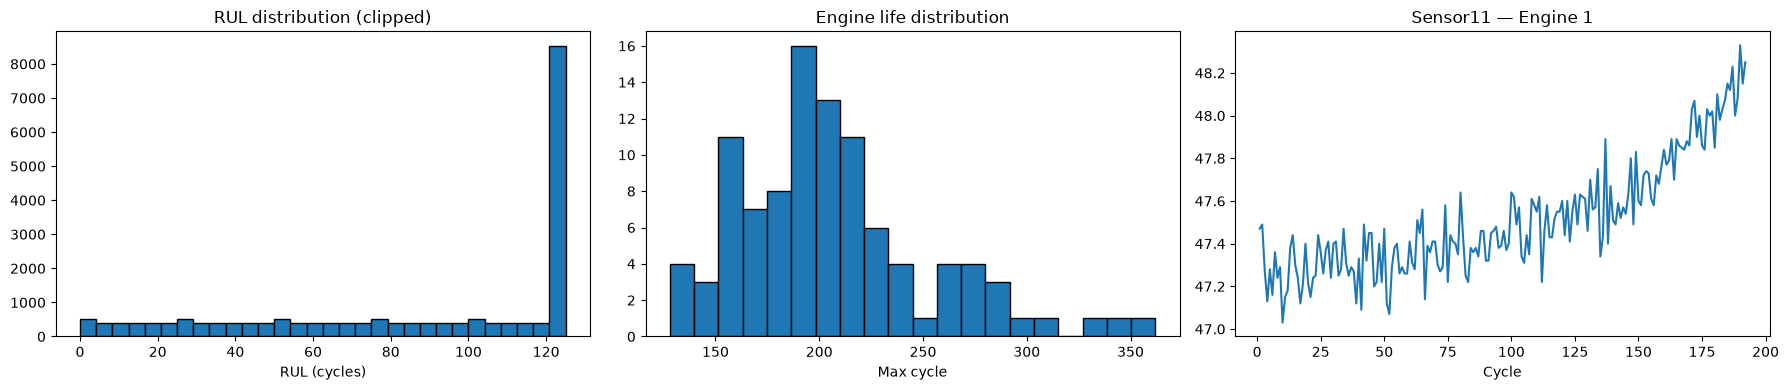

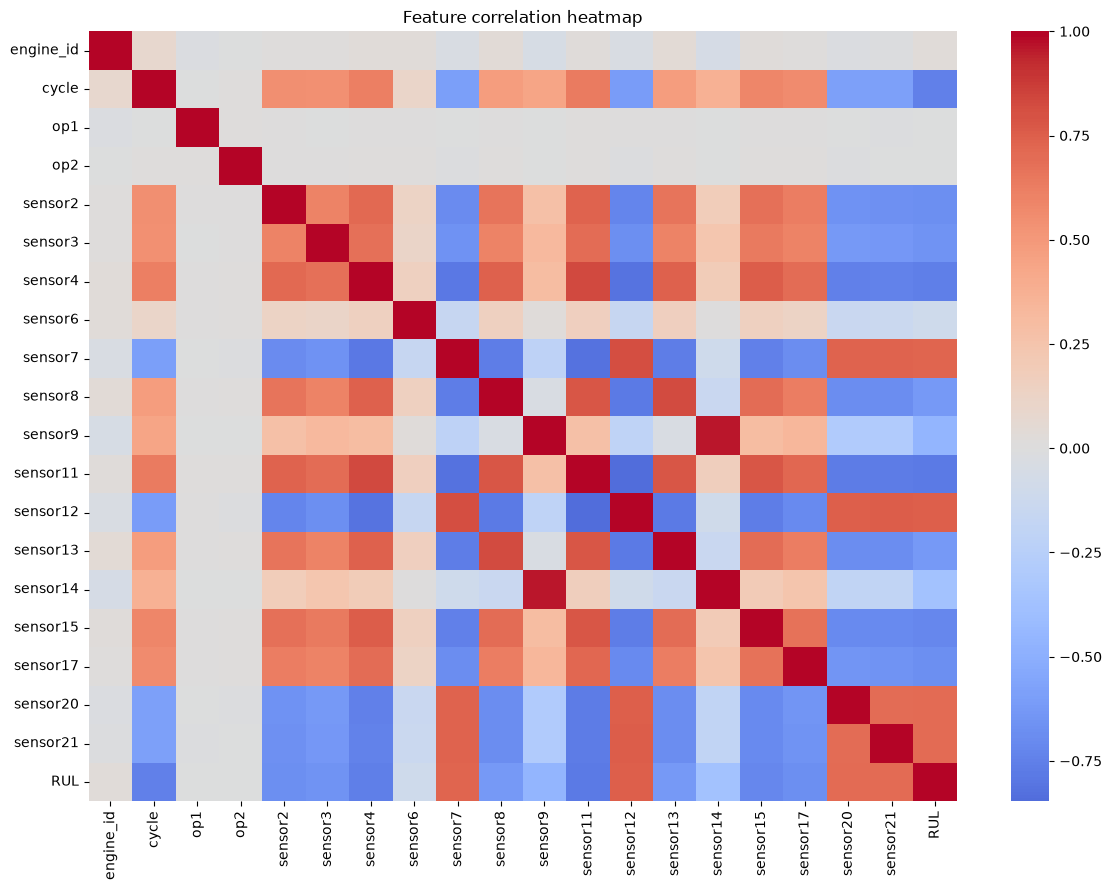

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(train_df["RUL"], bins=30, edgecolor="black")
axes[0].set_title("RUL distribution (clipped)")
axes[0].set_xlabel("RUL (cycles)")

engine_life = train_df.groupby("engine_id")["cycle"].max()
axes[1].hist(engine_life, bins=20, edgecolor="black")
axes[1].set_title("Engine life distribution")
axes[1].set_xlabel("Max cycle")

eng1 = train_df[train_df["engine_id"] == 1]
axes[2].plot(eng1["cycle"], eng1["sensor11"])
axes[2].set_title("Sensor11 — Engine 1")
axes[2].set_xlabel("Cycle")

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 10))
sns.heatmap(train_df.drop(columns=["max_cycle", "RUL_raw"]).corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap")
plt.show()


## 4. Feature set + leakage-safe split

`GroupShuffleSplit` on `engine_id` — no engine appears in both train and test.
This replaces the earlier row-wise `train_test_split`, which let cycles from
the same engine leak across the split.

In [9]:
FEATURE_COLS = [c for c in train_df.columns if c not in
                 ("RUL", "RUL_raw", "max_cycle", "engine_id")]

X = train_df[FEATURE_COLS]
y = train_df["RUL"]
groups = train_df["engine_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Engine overlap between train/test: {len(overlap)}  (must be 0)")
assert len(overlap) == 0


Engine overlap between train/test: 0  (must be 0)


## 5. GroupKFold cross-validation (honest metric, not a single split)

In [10]:
def run_group_kfold(X, y, groups, n_splits=5, **xgb_params):
    gkf = GroupKFold(n_splits=n_splits)
    maes, r2s = [], []
    for tr_idx, te_idx in gkf.split(X, y, groups):
        model = XGBRegressor(random_state=RANDOM_STATE, **xgb_params)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict(X.iloc[te_idx])
        maes.append(mean_absolute_error(y.iloc[te_idx], pred))
        r2s.append(r2_score(y.iloc[te_idx], pred))
    return np.array(maes), np.array(r2s)

XGB_PARAMS = dict(n_estimators=300, max_depth=6, learning_rate=0.05)

maes, r2s = run_group_kfold(X, y, groups, n_splits=5, **XGB_PARAMS)

print(f"Full-feature model  —  MAE: {maes.mean():.2f} ± {maes.std():.2f}   "
      f"R²: {r2s.mean():.4f} ± {r2s.std():.4f}")


Full-feature model  —  MAE: 11.39 ± 0.60   R²: 0.8391 ± 0.0153


## 6. Ablation test — is the model just counting cycles?

Same GroupKFold procedure, `cycle` removed from the feature set. If R² holds
up reasonably well without it, the sensors are doing real work.

In [11]:
ABLATION_COLS = [c for c in FEATURE_COLS if c != "cycle"]
X_ablation = train_df[ABLATION_COLS]

maes_abl, r2s_abl = run_group_kfold(X_ablation, y, groups, n_splits=5, **XGB_PARAMS)

print(f"Sensors-only model   —  MAE: {maes_abl.mean():.2f} ± {maes_abl.std():.2f}   "
      f"R²: {r2s_abl.mean():.4f} ± {r2s_abl.std():.4f}")
print()
retained = r2s_abl.mean() / r2s.mean() * 100
print(f"Sensors-only model retains {retained:.1f}% of full-model R².")


Sensors-only model   —  MAE: 13.49 ± 0.77   R²: 0.7967 ± 0.0131

Sensors-only model retains 94.9% of full-model R².


## 7. Final model — fit once on the full training split, used everywhere downstream

In [12]:
final_model = XGBRegressor(random_state=RANDOM_STATE, **XGB_PARAMS)
final_model.fit(X_train, y_train)

pred_test = final_model.predict(X_test)
print(f"Held-out split  —  MAE: {mean_absolute_error(y_test, pred_test):.2f}   "
      f"R²: {r2_score(y_test, pred_test):.4f}")


Held-out split  —  MAE: 10.74   R²: 0.8547


## 8. Feature importance + diagnostic plots

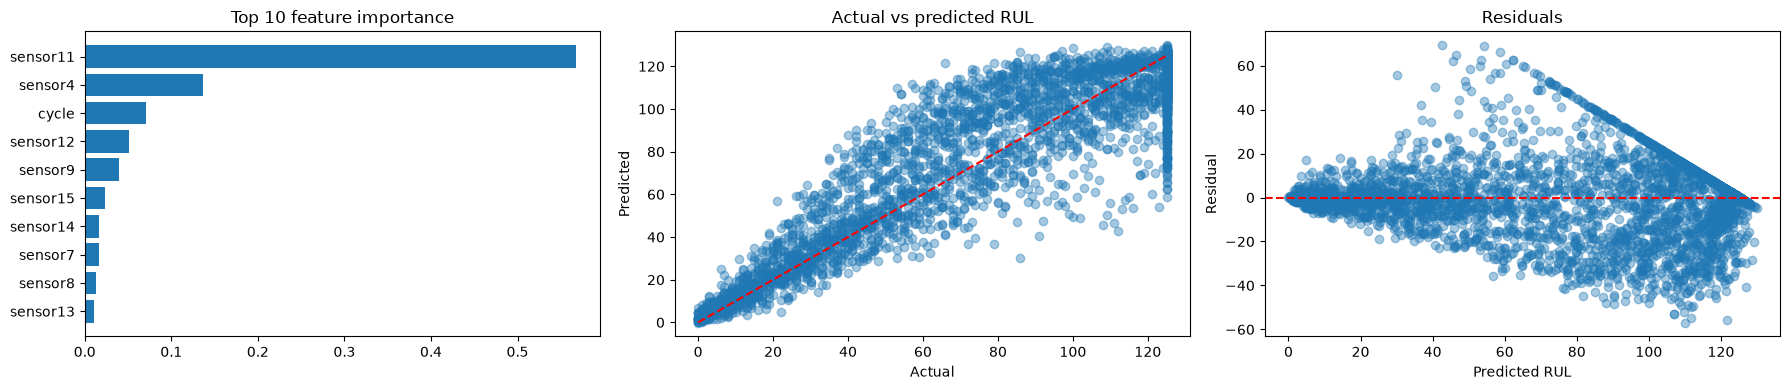

,Feature,Importance
10,sensor11,0.567028
5,sensor4,0.137179
0,cycle,0.071207
11,sensor12,0.051098
9,sensor9,0.039685
14,sensor15,0.023700
13,sensor14,0.016113
7,sensor7,0.015961
8,sensor8,0.012770
12,sensor13,0.011272


In [13]:
importance = (
    pd.DataFrame({"Feature": FEATURE_COLS, "Importance": final_model.feature_importances_})
    .sort_values("Importance", ascending=False)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].barh(importance["Feature"][:10][::-1], importance["Importance"][:10][::-1])
axes[0].set_title("Top 10 feature importance")

axes[1].scatter(y_test, pred_test, alpha=0.4)
axes[1].plot([0, RUL_CLIP], [0, RUL_CLIP], "r--")
axes[1].set_title("Actual vs predicted RUL")
axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")

residuals = y_test.values - pred_test
axes[2].scatter(pred_test, residuals, alpha=0.4)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Residuals")
axes[2].set_xlabel("Predicted RUL"); axes[2].set_ylabel("Residual")

plt.tight_layout()
plt.show()

importance.head(10)


## 9. SHAP explainability

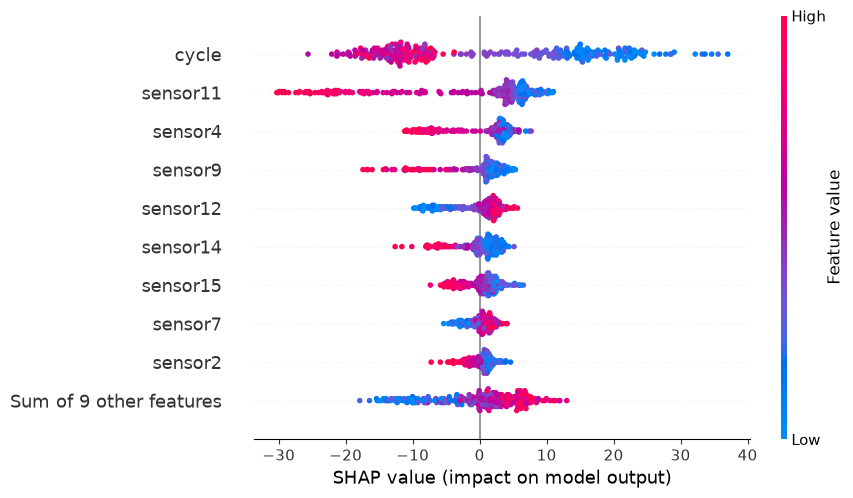

In [14]:
import shap

explainer = shap.TreeExplainer(final_model)
sample = X_test.sample(min(300, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer(sample)

shap.plots.beeswarm(shap_values, max_display=10)


## 10. Digital-twin snapshot (seeded — reproducible across reruns)

One snapshot cycle per engine, sampled from the 60-90% point of its life,
so engines look "currently in service" instead of "one cycle from failure".
Seeded with `RANDOM_STATE` so the same engines get the same snapshot cycle
every time this cell runs.

In [15]:
snap_rng = np.random.default_rng(RANDOM_STATE)

snapshot_rows = []
for eng in train_df["engine_id"].unique():
    eng_df = train_df[train_df["engine_id"] == eng]
    life = eng_df["cycle"].max()
    lo, hi = max(1, int(0.6 * life)), max(2, int(0.9 * life))
    snap_cycle = snap_rng.integers(lo, hi)
    row = eng_df[eng_df["cycle"] == snap_cycle]
    if len(row):
        snapshot_rows.append(row)

snapshot_df = pd.concat(snapshot_rows).reset_index(drop=True)
snapshot_df["Predicted_RUL"] = final_model.predict(snapshot_df[FEATURE_COLS])

snapshot_df[["engine_id", "cycle", "RUL", "Predicted_RUL"]].head()


,engine_id,cycle,RUL,Predicted_RUL
0,1,120,72,90.542274
1,2,238,49,62.728779
2,3,142,37,40.561825
3,4,138,51,60.848942
4,5,196,73,64.204056


## 11. Health index, failure risk, maintenance recommendation

In [16]:
snapshot_df["Health_Index"] = (snapshot_df["Predicted_RUL"] / RUL_CLIP).clip(0, 1) * 100
snapshot_df["Failure_Risk_%"] = 100 - snapshot_df["Health_Index"]

def recommendation(risk_pct):
    if risk_pct >= 80:
        return "Immediate Maintenance"
    elif risk_pct >= 50:
        return "Schedule Maintenance"
    return "Healthy"

snapshot_df["Recommendation"] = snapshot_df["Failure_Risk_%"].apply(recommendation)

print(snapshot_df["Failure_Risk_%"].describe())
snapshot_df[["engine_id", "cycle", "Predicted_RUL", "Health_Index",
             "Failure_Risk_%", "Recommendation"]].head(10)


count    100.000000
mean      53.941063
std       18.339138
min        9.953384
25%       43.422827
50%       53.484669
75%       68.124573
max       86.620132
Name: Failure_Risk_%, dtype: float64


,engine_id,cycle,Predicted_RUL,Health_Index,Failure_Risk_%,Recommendation
0,1,120,90.542274,72.433815,27.566185,Healthy
1,2,238,62.728779,50.183022,49.816978,Healthy
2,3,142,40.561825,32.449459,67.550537,Schedule Maintenance
3,4,138,60.848942,48.679153,51.320847,Schedule Maintenance
4,5,196,64.204056,51.363243,48.636757,Healthy
5,6,160,25.006031,20.004826,79.995178,Schedule Maintenance
6,7,161,107.641548,86.113235,13.886765,Healthy
7,8,121,25.898579,20.718864,79.281136,Schedule Maintenance
8,9,132,68.620346,54.896278,45.103722,Healthy
9,10,139,91.702972,73.362381,26.637619,Healthy


## 12. Export for the Streamlit dashboard

Persist the fitted model and the snapshot table so the dashboard loads
them instead of retraining / re-randomizing on every run.

In [49]:
import joblib

# Model
joblib.dump(
    final_model,
    "xgb_rul_model.pkl"
)

# Dashboard datasets
snapshot_df.to_csv(
    "digital_twin_snapshot.csv",
    index=False
)

train_df.to_csv(
    "train_processed.csv",
    index=False
)

test_last[
    [
        'engine_id',
        'Actual_RUL',
        'Predicted_RUL',
        'Actual_RUL_clipped'
    ]
].to_csv(
    "test_predictions.csv",
    index=False
)

importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("All dashboard files saved.")

All dashboard files saved.


In [18]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
c:\Users\Lenovo\Desktop\Kashisa Padhy\Industrial_Digital_Twin\notebook


In [19]:
import os

print(os.path.exists("../data"))
print(os.path.exists("data"))

True
False


In [20]:
import os

print(os.listdir("../data"))

['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


In [21]:
import os

print(os.path.abspath("../data"))

c:\Users\Lenovo\Desktop\Kashisa Padhy\Industrial_Digital_Twin\data


In [22]:
print(test_df.head())
print(test_df.shape)

   engine_id  cycle     op1     op2    op3  sensor1  sensor2  sensor3  \
0          1      1  0.0023  0.0003  100.0   518.67   643.02  1585.29   
1          1      2 -0.0027 -0.0003  100.0   518.67   641.71  1588.45   
2          1      3  0.0003  0.0001  100.0   518.67   642.46  1586.94   
3          1      4  0.0042  0.0000  100.0   518.67   642.44  1584.12   
4          1      5  0.0014  0.0000  100.0   518.67   642.51  1587.19   

   sensor4  sensor5  ...  sensor12  sensor13  sensor14  sensor15  sensor16  \
0  1398.21    14.62  ...    521.72   2388.03   8125.55    8.4052      0.03   
1  1395.42    14.62  ...    522.16   2388.06   8139.62    8.3803      0.03   
2  1401.34    14.62  ...    521.97   2388.03   8130.10    8.4441      0.03   
3  1406.42    14.62  ...    521.38   2388.05   8132.90    8.3917      0.03   
4  1401.92    14.62  ...    522.15   2388.03   8129.54    8.4031      0.03   

   sensor17  sensor18  sensor19  sensor20  sensor21  
0       392      2388     100.0     38

In [23]:
print(rul_test_df.head())
print(rul_test_df.shape)

   true_RUL
0       112
1        98
2        69
3        82
4        91
(100, 1)


In [24]:
test_last = (
    test_df
    .groupby('engine_id')
    .tail(1)
    .copy()
)

test_last.head()

,engine_id,cycle,op1,op2,op3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,521.79,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,521.74,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,520.83,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,521.88,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,521.00,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117


In [25]:
test_last.shape

(100, 26)

In [26]:
test_last = test_last.reset_index(drop=True)

test_last['Actual_RUL'] = (
    rul_test_df['true_RUL']
)

In [27]:
test_last[
    ['engine_id','Actual_RUL']
].head()

,engine_id,Actual_RUL
0,1,112
1,2,98
2,3,69
3,4,82
4,5,91


In [28]:
FEATURE_COLS = [
    'cycle',
    'op1','op2',
    'sensor2','sensor3','sensor4',
    'sensor6','sensor7','sensor8',
    'sensor9','sensor11','sensor12',
    'sensor13','sensor14','sensor15',
    'sensor17','sensor20','sensor21'
]

In [29]:
X_official = test_last[
    FEATURE_COLS
]

In [32]:
globals().keys()

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__vsc_ipynb_file__', '_i', '_ii', '_iii', '_i1', 'os', '_i2', '_i3', '_i4', '_i5', 'np', 'pd', 'plt', 'sns', 'GroupShuffleSplit', 'GroupKFold', 'mean_absolute_error', 'r2_score', 'XGBRegressor', 'RANDOM_STATE', 'RUL_CLIP', '_i6', 'DATA_DIR', 'COLS', '_load_real', '_generate_synthetic', 'train_df', 'test_df', 'rul_test_df', '_6', '_i7', 'max_cycle', 'constant_cols', '_i8', 'fig', 'axes', 'engine_life', 'eng1', '_i9', 'FEATURE_COLS', 'X', 'y', 'groups', 'gss', 'train_idx', 'test_idx', 'X_train', 'X_test', 'y_train', 'y_test', 'overlap', '_i10', 'run_group_kfold', 'XGB_PARAMS', 'maes', 'r2s', '_i11', 'ABLATION_COLS', 'X_ablation', 'maes_abl', 'r2s_abl', 'retained', '_i12', 'final_model', 'pred_test', '_i13', 'importance', 'residuals', '_13', '_i14', 'shap', 'explainer', 'sample', 'shap_values',

In [33]:
%who

ABLATION_COLS	 COLS	 DATA_DIR	 FEATURE_COLS	 GroupKFold	 GroupShuffleSplit	 RANDOM_STATE	 RUL_CLIP	 X	 
XGBRegressor	 XGB_PARAMS	 X_ablation	 X_official	 X_test	 X_train	 axes	 constant_cols	 eng	 
eng1	 eng_df	 engine_life	 explainer	 fig	 final_model	 groups	 gss	 hi	 
importance	 joblib	 life	 lo	 maes	 maes_abl	 max_cycle	 mean_absolute_error	 np	 
os	 overlap	 pd	 plt	 pred_test	 r2_score	 r2s	 r2s_abl	 recommendation	 
residuals	 retained	 row	 rul_test_df	 run_group_kfold	 sample	 shap	 shap_values	 snap_cycle	 
snap_rng	 snapshot_df	 snapshot_rows	 sns	 test_df	 test_idx	 test_last	 train_df	 train_idx	 
y	 y_test	 y_train	 


In [34]:
official_pred = final_model.predict(
    X_official
)

In [35]:
test_last['Predicted_RUL'] = official_pred

In [36]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    test_last['Actual_RUL'],
    test_last['Predicted_RUL']
)

rmse = np.sqrt(
    mean_squared_error(
        test_last['Actual_RUL'],
        test_last['Predicted_RUL']
    )
)

r2 = r2_score(
    test_last['Actual_RUL'],
    test_last['Predicted_RUL']
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 14.371325492858887
RMSE: 19.00085286685755
R²  : 0.7909324169158936


In [37]:
print(X_official.columns)
print(FEATURE_COLS)

Index(['cycle', 'op1', 'op2', 'sensor2', 'sensor3', 'sensor4', 'sensor6',
       'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13',
       'sensor14', 'sensor15', 'sensor17', 'sensor20', 'sensor21'],
      dtype='str')
['cycle', 'op1', 'op2', 'sensor2', 'sensor3', 'sensor4', 'sensor6', 'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13', 'sensor14', 'sensor15', 'sensor17', 'sensor20', 'sensor21']


In [38]:
(rul_test_df['true_RUL'] > 125).sum()

np.int64(11)

In [39]:
test_last['Actual_RUL_clipped'] = (
    test_last['Actual_RUL']
    .clip(upper=125)
)

In [40]:
mae_clip = mean_absolute_error(
    test_last['Actual_RUL_clipped'],
    test_last['Predicted_RUL']
)

rmse_clip = np.sqrt(
    mean_squared_error(
        test_last['Actual_RUL_clipped'],
        test_last['Predicted_RUL']
    )
)

r2_clip = r2_score(
    test_last['Actual_RUL_clipped'],
    test_last['Predicted_RUL']
)

print("Clipped MAE :", mae_clip)
print("Clipped RMSE:", rmse_clip)
print("Clipped R²  :", r2_clip)

Clipped MAE : 13.301325798034668
Clipped RMSE: 17.77563001586547
Clipped R²  : 0.8032383918762207


In [41]:
print(test_last.shape)
print(test_last['engine_id'].nunique())

(100, 29)
100


In [42]:
test_last[['engine_id','cycle']].head()

,engine_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98


In [43]:
set(FEATURE_COLS) - set(X_official.columns)

set()

In [44]:
set(X_official.columns) - set(FEATURE_COLS)

set()

In [46]:
%who DataFrame

X	 X_ablation	 X_official	 X_test	 X_train	 eng1	 eng_df	 importance	 max_cycle	 
row	 rul_test_df	 sample	 snapshot_df	 test_df	 test_last	 train_df	 


In [47]:
print(test_last.columns)

Index(['engine_id', 'cycle', 'op1', 'op2', 'op3', 'sensor1', 'sensor2',
       'sensor3', 'sensor4', 'sensor5', 'sensor6', 'sensor7', 'sensor8',
       'sensor9', 'sensor10', 'sensor11', 'sensor12', 'sensor13', 'sensor14',
       'sensor15', 'sensor16', 'sensor17', 'sensor18', 'sensor19', 'sensor20',
       'sensor21', 'Actual_RUL', 'Predicted_RUL', 'Actual_RUL_clipped'],
      dtype='str')


In [48]:
test_last[
    [
        'engine_id',
        'Actual_RUL',
        'Predicted_RUL',
        'Actual_RUL_clipped'
    ]
].to_csv(
    "test_predictions.csv",
    index=False
)